# 05 · Double / debiased machine learning (partially linear model)

Model: $Y = \theta D + g(X) + \varepsilon$, $\;D = m(X) + v$, with $g$ and $m$ **non-linear**.
This is the price-elasticity setting: $D$ = log price, $Y$ = log sales, $X$ = calendar, traffic, lags.

**Idea (Frisch–Waugh–Lovell + ML):** remove from both $Y$ and $D$ the part predictable from $X$,
then regress residual on residual:

$$\tilde Y = Y - \hat\ell(X),\quad \tilde D = D - \hat m(X),\quad \hat\theta = \frac{\sum \tilde D_i \tilde Y_i}{\sum \tilde D_i^2}$$

where $\ell(X)=E[Y\mid X]$. Two ingredients make this valid with flexible ML:
1. **Orthogonality:** small errors in $\hat\ell,\hat m$ affect $\hat\theta$ only to second order.
2. **Cross-fitting:** each residual comes from a model that never saw that observation.

**Library check:** `doubleml.DoubleMLPLR` (`score="partialling out"`) with identical learners and folds.

In [1]:
import warnings
warnings.filterwarnings("ignore")  # silence library deprecation/progress chatter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import KFold
import doubleml as dml

import causalsim as cs
from causalsim.plotting import use_style, truth_line

use_style()

sim = cs.plr_nonlinear(n=2_000, theta=0.5, seed=0)
df = sim.data
X_cols = [c for c in df.columns if c.startswith("X")]
X, D, Y = df[X_cols].to_numpy(), df.D.to_numpy(), df.Y.to_numpy()
print(sim)

SimResult(n=2000, cols=['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'D', 'Y'], truth={theta=0.5})


## 1. Baseline: linear regression is biased here

In [2]:
Xo = np.column_stack([np.ones(len(Y)), D, X])
theta_ols = np.linalg.lstsq(Xo, Y, rcond=None)[0][1]
print(f"OLS of Y on D and X: {theta_ols:.3f}   (truth {sim.truth['theta']})")

OLS of Y on D and X: 0.931   (truth 0.5)


Linear controls cannot absorb $g(X)$ and $m(X)$, so the leftover confounding leaks into $\hat\theta$.

## 2. From scratch: cross-fitted partialling-out

Standard error from the orthogonal score $\psi_i = (\tilde Y_i - \theta\tilde D_i)\,\tilde D_i$ and
$J = -\overline{\tilde D^2}$: $\;\widehat{\text{Var}}(\hat\theta) = \dfrac{\overline{\psi^2}}{J^2\,n}$.

In [3]:
def learner():
    return HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=0)


def dml_plr(X, D, Y, make_learner, n_folds=5, seed=1, folds=None, cross_fit=True):
    n = len(Y)
    if not cross_fit:  # fit and predict on the SAME data -- for demonstration only
        y_res = Y - make_learner().fit(X, Y).predict(X)
        d_res = D - make_learner().fit(X, D).predict(X)
    else:
        if folds is None:
            folds = list(KFold(n_folds, shuffle=True, random_state=seed).split(X))
        y_res, d_res = np.zeros(n), np.zeros(n)
        for tr, te in folds:
            y_res[te] = Y[te] - make_learner().fit(X[tr], Y[tr]).predict(X[te])
            d_res[te] = D[te] - make_learner().fit(X[tr], D[tr]).predict(X[te])
    theta = d_res @ y_res / (d_res @ d_res)
    psi = (y_res - theta * d_res) * d_res
    se = np.sqrt(np.mean(psi ** 2) / np.mean(d_res ** 2) ** 2 / n)
    return theta, se, folds


theta, se, folds = dml_plr(X, D, Y, learner)
print(f"DML: {theta:.4f} ± {1.96*se:.4f}")

DML: 0.5054 ± 0.0490


## 3. Library check: DoubleML

In [4]:
dml_data = dml.DoubleMLData(df, y_col="Y", d_cols="D", x_cols=X_cols)
plr = dml.DoubleMLPLR(dml_data, learner(), learner(), n_folds=5, score="partialling out", draw_sample_splitting=False)
plr.set_sample_splitting([folds])
plr.fit()

np.testing.assert_allclose(theta, plr.coef[0], rtol=1e-8)
np.testing.assert_allclose(se, plr.se[0], rtol=1e-8)
assert abs(theta - sim.truth["theta"]) < 0.1
print(f"✓ matches DoubleMLPLR exactly: {plr.coef[0]:.6f} ± {plr.se[0]:.6f}")
plr.summary

✓ matches DoubleMLPLR exactly: 0.505355 ± 0.025008


,coef,std err,t,P>|t|,2.5 %,97.5 %
D,0.505355,0.025008,20.207613,8.390832e-91,0.45634,0.55437


## 4. Break it: no cross-fitting

Make the failure obvious with an extreme over-fitter: **1-nearest-neighbour**. In-sample, it predicts every
training point perfectly, so $\tilde D = 0$ and $\tilde Y = 0$ exactly; $\hat\theta = 0/0$ is undefined (`nan`).
With cross-fitting, the same learner is merely noisy.

In [5]:
one_nn = lambda: KNeighborsRegressor(n_neighbors=1)
for cf in (True, False):
    th, s, _ = dml_plr(X, D, Y, one_nn, cross_fit=cf)
    label = "cross-fitted" if cf else "in-sample   "
    print(f"1-NN, {label}: θ = {th:8.3f}" + (f" ± {1.96*s:.3f}" if np.isfinite(s) else ""))

1-NN, cross-fitted: θ =    0.652 ± 0.048
1-NN, in-sample   : θ =      nan


## 5. Monte Carlo: OLS vs in-sample DML vs cross-fitted DML

With a realistic, regularized learner the in-sample damage is subtler. Watch the **coverage** column: the share of
datasets whose 95% interval contains the truth. 25 replications take a minute or two.

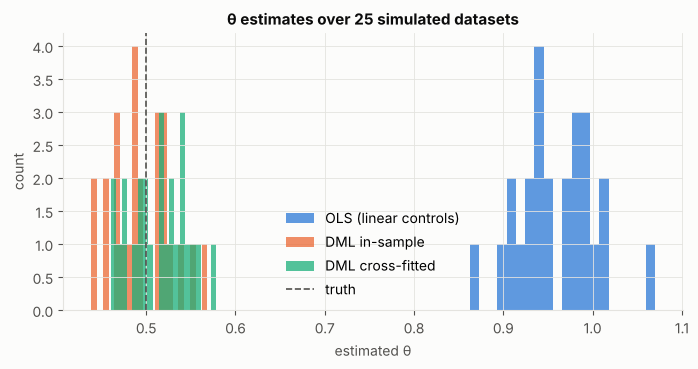

,mean,sd,coverage
method,,,
OLS (linear controls),0.959,0.044,NaN
DML in-sample,0.494,0.034,0.84
DML cross-fitted,0.514,0.032,0.96


In [6]:
rows = []
for s in range(25):
    d = cs.plr_nonlinear(n=2_000, seed=100 + s).data
    Xs, Ds, Ys = d[X_cols].to_numpy(), d.D.to_numpy(), d.Y.to_numpy()
    ols_ = np.linalg.lstsq(np.column_stack([np.ones(len(Ys)), Ds, Xs]), Ys, rcond=None)[0][1]
    th_cf, se_cf, _ = dml_plr(Xs, Ds, Ys, learner)
    th_in, se_in, _ = dml_plr(Xs, Ds, Ys, learner, cross_fit=False)
    rows += [
        {"method": "OLS (linear controls)", "estimate": ols_, "covers": np.nan},
        {"method": "DML in-sample", "estimate": th_in, "covers": float(abs(th_in - 0.5) <= 1.96 * se_in)},
        {"method": "DML cross-fitted", "estimate": th_cf, "covers": float(abs(th_cf - 0.5) <= 1.96 * se_cf)},
    ]
mc = pd.DataFrame(rows)

fig, ax = plt.subplots()
for method, g in mc.groupby("method", sort=False):
    ax.hist(g.estimate, bins=20, alpha=0.75, label=method)
truth_line(ax, 0.5)
ax.set(title="θ estimates over 25 simulated datasets", xlabel="estimated θ", ylabel="count")
ax.legend()
plt.show()
mc.groupby("method", sort=False).agg(mean=("estimate", "mean"), sd=("estimate", "std"), coverage=("covers", "mean")).round(3)

**What to notice**

- OLS is far off: linear controls cannot remove non-linear confounding.
- Cross-fitted DML is close to 0.5. Some finite-sample bias remains, because the ML learners are imperfect.
- In-sample fitting is fragile: catastrophic for an interpolating learner. For a regularized one the point estimate
  can look fine while the intervals are too narrow (coverage well below 95%), because overfit residuals understate the noise.
- 25 replications is a small Monte Carlo; coverage estimates move by several points between runs. Use more for real conclusions.

**Exercises**
1. Swap in `RandomForestRegressor` or `LassoCV` (with polynomial features). Which nuisance model matters more, $\hat\ell$ or $\hat m$?
2. Implement the alternative "IV-type" score ($\tilde Y = Y - \hat g(X)$ using an estimate of $g$, not $\ell$) and compare with `score="IV-type"`.
3. Repeat cross-fitting with 5 different fold splits and take the median (what `n_rep` does in DoubleML).
4. Apply DML to `cs.retail_pricing()`: $Y=\log(\text{purch}_1)$, $D=\log(\text{price}_1)$, $X$ = day-of-week dummies + log visitors.
   Why doesn't DML fix the bias from the hidden demand shock? (Answer: it is unobserved; see notebook 04.)